In [215]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

In [216]:
#Importing all the needed libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split # Spliting the datasets into random train and test subsets.

In [217]:
dataZ = pd.read_csv('../data/alzheimer_disease_patient.csv')

In [218]:
#print the whole dataset , and it has 2158 rows & 35 columns
dataZ

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1.0,0.0,0.0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0.0,1.0,0.0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1.0,0.0,0.0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0.0,0.0,0.0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1.0,0.0,0.0,XXXConfid
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2153,4936,69,0,0,1,35.288922,0,12.473892,4.293538,9.733991,...,1,1,3.916521,0,0,1,1.0,0.0,1.0,XXXConfid
2154,4937,90,0,0,3,39.661465,1,6.957363,5.601585,7.169252,...,0,0,6.528765,0,0,0,0.0,1.0,0.0,XXXConfid
2155,4936,69,0,0,1,35.288922,0,12.473892,4.293538,9.733991,...,1,1,3.916521,0,0,1,1.0,0.0,1.0,XXXConfid
2156,4937,90,0,0,3,39.661465,1,6.957363,5.601585,7.169252,...,0,0,6.528765,0,0,0,0.0,1.0,0.0,XXXConfid


In [219]:
dataZ.head()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,4751,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,...,0,0,1.725883,0,0,0,1.0,0.0,0.0,XXXConfid
1,4752,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,...,0,0,2.592424,0,0,0,0.0,1.0,0.0,XXXConfid
2,4753,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,...,0,0,7.119548,0,1,0,1.0,0.0,0.0,XXXConfid
3,4754,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,...,0,1,6.481226,0,0,0,0.0,0.0,0.0,XXXConfid
4,4755,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,...,0,0,0.014691,0,0,1,1.0,0.0,0.0,XXXConfid


# **Data Preprocessing**





# 1.Dealing with redundancies

In [220]:
#columns and rows by using Shape method
dataZ.shape

(2158, 35)

In [221]:
#we used the Drop method to remove duplicate rows
dataZ.drop_duplicates(inplace=True)

In [222]:
# we had 9 rows repeated
dataZ.shape

(2149, 35)

# 2.Dealing with Missing values

In [223]:
#check each individual cell in the dataset to determine if it contains a null value or not
dataZ.isnull()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2145,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2146,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2147,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [224]:
#checks whether any missing values exist in each column
dataZ.isnull().any()

,0
PatientID,False
Age,False
Gender,False
Ethnicity,False
EducationLevel,False
BMI,False
Smoking,False
AlcoholConsumption,False
PhysicalActivity,False
DietQuality,False


In [225]:
#To cheack how many missing values in each coulmn
dataZ.isnull().sum()

,0
PatientID,0
Age,0
Gender,0
Ethnicity,0
EducationLevel,0
BMI,0
Smoking,0
AlcoholConsumption,0
PhysicalActivity,0
DietQuality,0


We have 7 null values one for each column (CholesterolTotal,CholesterolHDL,DifficultyCompletingTasks,FunctionalAssessment,ADL
,Forgetfulness,Diagnosis)

In [226]:
# 0 , 1 columns replaced with Mode
binary_cols = [
    'DifficultyCompletingTasks',
    'Forgetfulness',
    'Diagnosis'
]

for col in binary_cols:
    if col in dataZ.columns and dataZ[col].isnull().sum() > 0:
        dataZ[col].fillna(dataZ[col].mode()[0], inplace=True)

In [227]:
# The median is used here because these assessments may have outliers, and the median is less affected by extreme values
median_cols = [
    'FunctionalAssessment',
    'ADL',
]
for col in median_cols:
    if col in dataZ.columns and dataZ[col].isnull().sum() > 0:
        dataZ[col].fillna(dataZ[col].median(), inplace=True)


In [228]:
#The mean is used here because cholesterol levels are continuous
numeric_cols = dataZ.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    if (
        dataZ[col].isnull().sum() > 0
        and col not in binary_cols
        and col not in median_cols
    ):
        dataZ[col].fillna(dataZ[col].mean(), inplace=True)

In [229]:
#To ensure that there is no missing data
dataZ.isnull().any()

,0
PatientID,False
Age,False
Gender,False
Ethnicity,False
EducationLevel,False
BMI,False
Smoking,False
AlcoholConsumption,False
PhysicalActivity,False
DietQuality,False


# 3.Dealing with Outliers


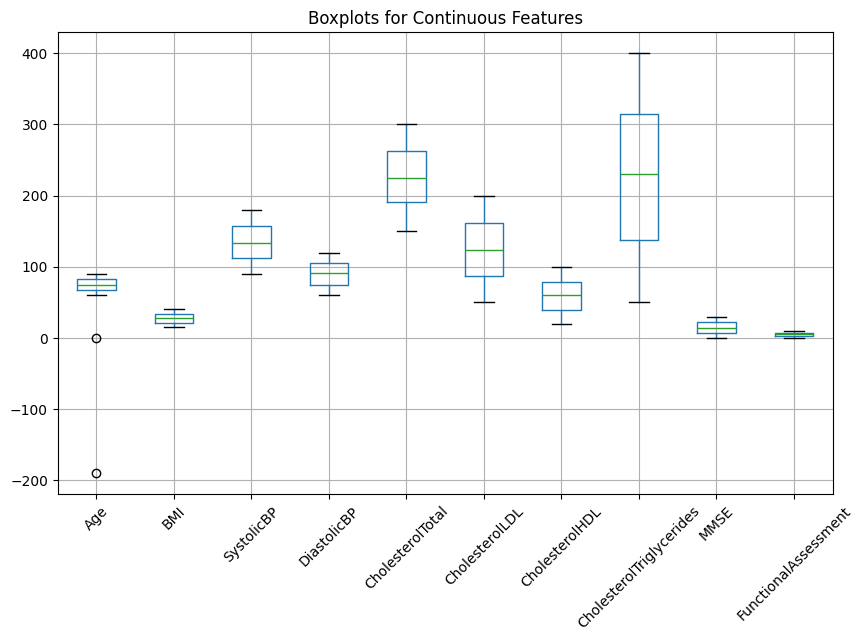

In [230]:
# Boxplots for continuous columns to visualize and detect outliers
continuous_cols = [
    'Age',
    'BMI',
    'SystolicBP',
    'DiastolicBP',
    'CholesterolTotal',
    'CholesterolLDL',
    'CholesterolHDL',
    'CholesterolTriglycerides',
    'MMSE',
    'FunctionalAssessment'
]
plt.figure(figsize=(10, 6))
dataZ[continuous_cols].boxplot(rot=45)
plt.title("Boxplots for Continuous Features")
plt.show()

In [231]:
#Dealing with the outliers we have in column Age ( in a IQR Method)
#We used the IQR method because it effectively handles outliers in skewed data, and replacing them with the median ensures stability without distorting the dataset
Q1 = dataZ['Age'].quantile(0.25)
Q3 = dataZ['Age'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
median_value = dataZ['Age'].median()

# Replace outliers
dataZ['Age'] = dataZ['Age'].apply(lambda x: median_value if x < lower_bound or x > upper_bound else x)

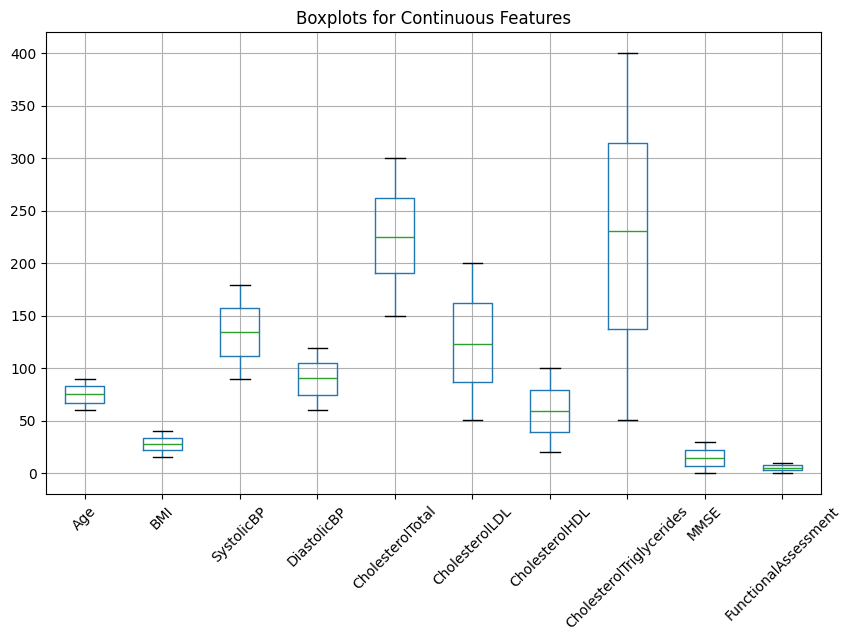

In [232]:
#To make sure the outliers are gone
plt.figure(figsize=(10, 6))
dataZ[continuous_cols].boxplot(rot=45)
plt.title("Boxplots for Continuous Features")
plt.show()

# 4.Scaling

In [233]:
scaler = MinMaxScaler()

# Select only the numerical columns that actually need scaling
# (we exclude binary features like 0/1 because they are already on a unified scale)
num_for_scaling = [c for c in numeric_cols if c not in binary_cols]

# Apply Min-Max scaling to the selected continuous numerical columns
dataZ[num_for_scaling] = scaler.fit_transform(dataZ[num_for_scaling])

# Print the shape to verify that no rows/columns were lost during preprocessing
print("Shape after preprocessing:", dataZ.shape)

# Preview the preprocessed dataset
dataZ.head()


Shape after preprocessing: (2149, 35)


,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis,DoctorInCharge
0,0.000000,0.433333,0.0,0.0,0.666667,0.316960,0.0,0.665183,0.633375,0.133931,...,0.0,0.0,0.172486,0.0,0.0,0.0,1.0,0.0,0.0,XXXConfid
1,0.000466,0.966667,0.0,0.0,0.000000,0.473058,0.0,0.227170,0.762862,0.050995,...,0.0,0.0,0.259154,0.0,0.0,0.0,0.0,1.0,0.0,XXXConfid
2,0.000931,0.433333,0.0,1.0,0.333333,0.111553,0.0,0.978276,0.785408,0.181896,...,0.0,0.0,0.711936,0.0,1.0,0.0,1.0,0.0,0.0,XXXConfid
3,0.001397,0.466667,1.0,0.0,0.333333,0.752163,1.0,0.610751,0.843804,0.743443,...,0.0,1.0,0.648094,0.0,0.0,0.0,0.0,0.0,0.0,XXXConfid
4,0.001862,0.966667,0.0,0.0,0.000000,0.228472,0.0,0.923204,0.631707,0.078698,...,0.0,0.0,0.001341,0.0,0.0,1.0,1.0,0.0,0.0,XXXConfid


# 5.Rearranging columns and dropping non-informative attributes

In [234]:
#We droppped the last column (DoctorInCharge) cause its String , so it won't effect our numerical work.
#Also we dropped it cause it have the same value for all the rows, so it will not effect our data if we've dropped it.
dataZ = dataZ.drop('DoctorInCharge', axis=1)

In [235]:
dataZ.head(1)

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
0,0.0,0.433333,0.0,0.0,0.666667,0.31696,0.0,0.665183,0.633375,0.133931,...,0.652102,0.0,0.0,0.172486,0.0,0.0,0.0,1.0,0.0,0.0


# **EDA**

## Basic summary statistics


In [236]:
#printing the statistics for numerical columns , we used round(2) cause it gives better readability
dataZ.describe().round(2)

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
count,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,...,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00,2149.00
mean,0.50,0.50,0.51,0.23,0.43,0.51,0.29,0.50,0.49,0.50,...,0.51,0.21,0.16,0.50,0.21,0.16,0.15,0.16,0.30,0.35
std,0.29,0.30,0.50,0.33,0.30,0.29,0.45,0.29,0.29,0.29,...,0.29,0.41,0.36,0.29,0.40,0.37,0.36,0.37,0.46,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.25,0.23,0.00,0.00,0.33,0.26,0.00,0.26,0.26,0.25,...,0.26,0.00,0.00,0.23,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.50,0.50,1.00,0.00,0.33,0.51,0.00,0.50,0.48,0.51,...,0.51,0.00,0.00,0.50,0.00,0.00,0.00,0.00,0.00,0.00
75%,0.75,0.77,1.00,0.33,0.67,0.75,1.00,0.76,0.74,0.76,...,0.75,0.00,0.00,0.76,0.00,0.00,0.00,0.00,1.00,1.00
max,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [237]:
dataZ.corr()

,PatientID,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
PatientID,1.000000,0.003052,-0.043665,-0.007608,-0.001729,-0.034228,0.021907,-0.020733,-0.011424,-0.018490,...,0.023948,0.005748,-0.033700,-0.019334,0.004430,0.010772,-0.011987,0.029727,0.001448,0.042466
Age,0.003052,1.000000,0.029922,0.027803,-0.059902,-0.017325,0.019994,0.006655,-0.010133,-0.023825,...,0.006020,0.013783,0.038883,-0.039183,0.009035,0.027566,-0.009455,0.013934,-0.019260,-0.005357
Gender,-0.043665,0.029922,1.000000,-0.003660,-0.007070,0.005928,0.016650,0.004330,-0.035795,0.010942,...,0.034077,0.003880,0.006099,0.004181,-0.030583,0.017506,0.025919,-0.001636,-0.028537,-0.021942
Ethnicity,-0.007608,0.027803,-0.003660,1.000000,0.026516,-0.003176,0.031485,0.008363,0.020498,-0.018184,...,-0.005226,0.003687,-0.019363,0.010381,0.022431,-0.018132,-0.030035,0.019363,-0.034619,-0.014105
EducationLevel,-0.001729,-0.059902,-0.007070,0.026516,1.000000,-0.023514,-0.009904,-0.012646,-0.016703,0.017412,...,0.020046,-0.000165,0.010473,0.032037,-0.008168,-0.017568,-0.019950,0.013033,-0.008685,-0.044747
BMI,-0.034228,-0.017325,0.005928,-0.003176,-0.023514,1.000000,0.020437,-0.008997,0.000742,0.019922,...,-0.031573,0.029293,0.035276,-0.009517,-0.015859,-0.031840,-0.015901,-0.039400,0.071131,0.026989
Smoking,0.021907,0.019994,0.016650,0.031485,-0.009904,0.020437,1.000000,0.008363,0.010760,-0.002048,...,-0.032370,0.020339,-0.014763,-0.029037,0.004498,-0.028403,-0.009977,0.001741,0.018011,-0.004247
AlcoholConsumption,-0.020733,0.006655,0.004330,0.008363,-0.012646,-0.008997,0.008363,1.000000,0.021696,0.020117,...,-0.016018,-0.029418,0.013657,-0.008672,-0.032798,0.015521,0.019117,-0.002712,-0.024121,-0.008896
PhysicalActivity,-0.011424,-0.010133,-0.035795,0.020498,-0.016703,0.000742,0.010760,0.021696,1.000000,0.011085,...,-0.002239,0.008709,-0.014253,-0.012832,-0.009397,-0.020407,-0.013629,0.031169,0.009837,0.005882
DietQuality,-0.018490,-0.023825,0.010942,-0.018184,0.017412,0.019922,-0.002048,0.020117,0.011085,1.000000,...,-0.008909,0.012537,-0.014033,-0.008052,0.002628,-0.026271,0.029087,0.045737,0.006175,0.008470


In [238]:
#here we print the columns and rows by using Shape method
dataZ.shape

(2149, 34)

# **Data visualization**

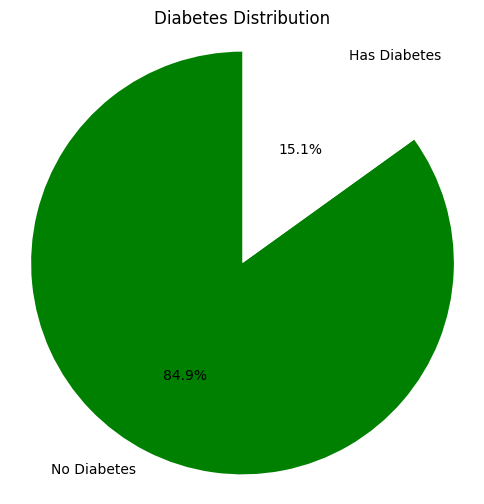

In [239]:
#This pie chart shows the distribution of diabetes status in the dataset, with segments for 'No Diabetes' and 'Has Diabetes', displaying their percentages
#and thankfully people with diabetes are less than who don't have it
labels = ['No Diabetes', 'Has Diabetes']
sizes = dataZ['Diabetes'].value_counts()
plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=['green','white'])
plt.title('Diabetes Distribution')
plt.axis('equal')
plt.show()

# **Spliting the data**

In [240]:
# Since 'Diagnosis' is the last column in our data , and the features are all other columns we used this method
X = dataZ.iloc[:, :-1] #All rows & columns except the last one
y = dataZ.iloc[:, -1]  #All rows but only the last column (Diagnosis)

In [241]:
# Assuming our feature data is in 'X' and our target is 'y'
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [269]:
print('Train set shape:', X_train.shape, y_train.shape)
print('Test set shape:', X_test.shape, y_test.shape)

Train set shape: (1504, 33) (1504,)
Test set shape: (645, 33) (645,)


# **Evaluation Models**

In [242]:
#importing all needed ML Libraries & ML Models

#import train & set
from sklearn.model_selection import train_test_split # Spliting the datasets into random train and test subsets.

# 1.Logistic Regression Model
from sklearn.linear_model import LogisticRegression
# 2.K-Nearest Neighbor Model
from sklearn.neighbors import KNeighborsClassifier
# 3.Decision Tree Model
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_graphviz
# 4.Random Forest Model
from sklearn.ensemble import RandomForestClassifier
# 5.Naive Bayes Model
from sklearn.naive_bayes import GaussianNB
# 6.Support Vector Machine Model
from sklearn.svm import SVC

# Model Evaluation Metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, accuracy_score, roc_curve, auc, roc_auc_score
from sklearn.metrics import jaccard_score, f1_score, log_loss

# import pipline & scaler for some models
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

## 1.Logistic Regression

In [243]:
#creating our LG model
logmodel = LogisticRegression()
#training our model
logmodel.fit(X_train,y_train)
#make predictions based on the X (training features) we gave
pred = logmodel.predict(X_test)
#To get probaility
pred_proba = logmodel.predict_proba(X_test)


In [270]:
# Training accuracy
train_accuracy_lr = accuracy_score(y_train, logmodel.predict(X_train))
print("Logistic Regression Model's Accuracy while training: {:.2f}".format(train_accuracy_lr))

# Testing accuracy
test_accuracy_lr = accuracy_score(y_test, logmodel.predict(X_test))
print("Logistic Regression Model's Accuracy while testing: {:.2f}".format(test_accuracy_lr))

Logistic Regression Model's Accuracy while training: 0.86
Logistic Regression Model's Accuracy while testing: 0.80


In [244]:
# y_test: true labels for the test set.
# pred: The predicted labels from the model
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[355  46]
 [ 80 164]]
              precision    recall  f1-score   support

         0.0       0.82      0.89      0.85       401
         1.0       0.78      0.67      0.72       244

    accuracy                           0.80       645
   macro avg       0.80      0.78      0.79       645
weighted avg       0.80      0.80      0.80       645



In [245]:
accuracy_lr = accuracy_score(y_test,pred)
jaccard_lr = jaccard_score(y_test, pred, pos_label=1)
f1_lr = f1_score(y_test, pred, pos_label=1)
log_loss_lr = log_loss(y_test, pred_proba)

print(f"Accuracy: {accuracy_lr:.4f}")
print(f"Jaccard Score: {jaccard_lr:.4f}")
print(f"F1-Score: {f1_lr:.4f}")
print(f"Log Loss: {log_loss_lr:.4f}")


Accuracy: 0.8047
Jaccard Score: 0.5655
F1-Score: 0.7225
Log Loss: 0.4319


Confusion matrix


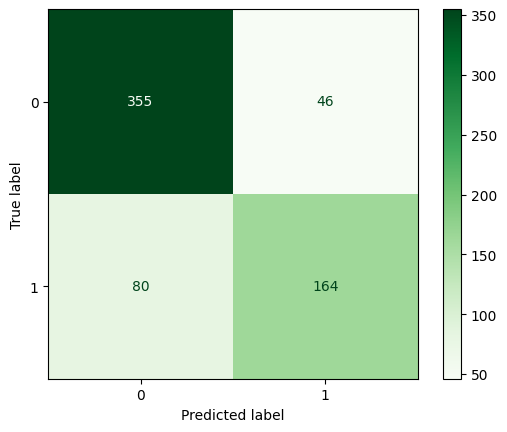

Normalized confusion matrix


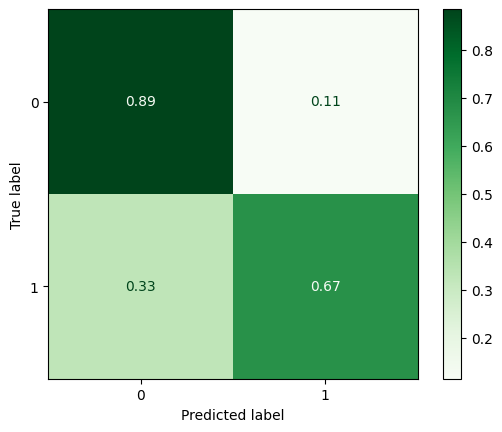

In [246]:
# Confusion matrix before normalization
print('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap='Greens')
plt.show()

# Confusion matrix after normalization
print('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap='Greens')
plt.show()

## 2.KNN

In [247]:
#creating our KNN model
knn = KNeighborsClassifier(n_neighbors=4)
#training our model
knn.fit(X_train,y_train)
#make predictions based on the X (training features) we gave
pred = knn.predict(X_test)

In [280]:
# Training accuracy
train_accuracy_knn = accuracy_score(y_train, knn.predict(X_train))
print("K-Nearest Neighbor Model's Accuracy while training: {:.2f}".format(train_accuracy_knn))

# Testing accuracy
test_accuracy_knn = accuracy_score(y_test, knn.predict(X_test))
print("K-Nearest Neighbor Model's Accuracy while testing: {:.2f}".format(test_accuracy_knn))

K-Nearest Neighbor Model's Accuracy while training: 0.79
K-Nearest Neighbor Model's Accuracy while testing: 0.66


In [248]:
#display Confusion matrix & classification
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[367  34]
 [183  61]]
              precision    recall  f1-score   support

         0.0       0.67      0.92      0.77       401
         1.0       0.64      0.25      0.36       244

    accuracy                           0.66       645
   macro avg       0.65      0.58      0.57       645
weighted avg       0.66      0.66      0.62       645



In [249]:
accuracy_knn = accuracy_score(y_test,pred)
jaccard_knn = jaccard_score(y_test, pred, pos_label=1)
f1_knn = f1_score(y_test, pred, pos_label=1)

print(f"Accuracy: {accuracy_knn:.4f}")
print(f"Jaccard Score: {jaccard_knn:.4f}")
print(f"F1-Score: {f1_knn:.4f}")
print(f"Log Loss: NA (KNN doesn't support probability estimates)")

Accuracy: 0.6636
Jaccard Score: 0.2194
F1-Score: 0.3599
Log Loss: NA (KNN doesn't support probability estimates)


Confusion matrix


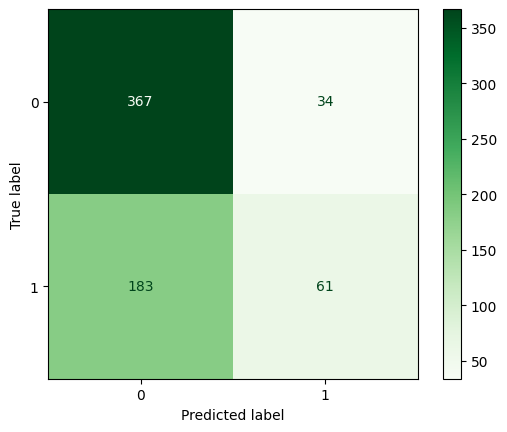

Normalized confusion matrix


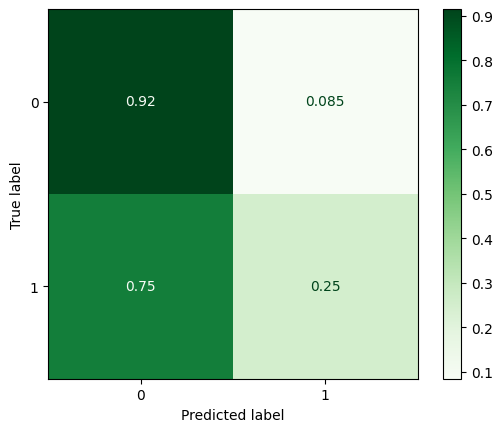

In [250]:
#Confusion matrix before normalization
print ('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap ='Greens')
plt.show()

# Confusion matrix after normalization
print ('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap ='Greens')
plt.show()

[[388  13]
 [170  74]]


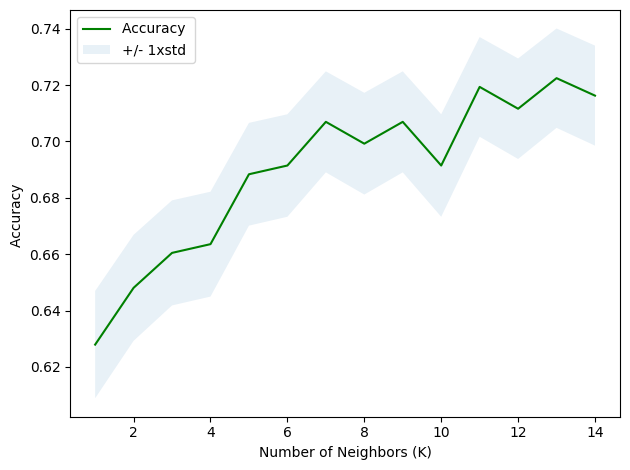

The best accuracy was 0.7224806201550388 with k= 13


In [282]:
# Finding Optimal k Value for KNN
Ks = 15    # range of k values to evaluate is from 1 to 14.
mean_accKNN = np.zeros((Ks-1)) # Array initialized with zeros to store mean accuracy for each k
std_accKNN = np.zeros((Ks-1)) # is set up to hold the standard deviation of accuracy for each k
ConfusionMxKNN = []; # empty list that could potentially store confusion matrices

# Train and Evaluate Model for Different k Values
for n in range(1,Ks):

    #Train Model and Predict
    neigh = KNeighborsClassifier(n_neighbors = n).fit(X_train,y_train)
    yKNNhat = neigh.predict(X_test)   # Make predictions on the test set
    mean_accKNN[n-1] = accuracy_score(y_test, yKNNhat)    # استخدام accuracy_score مباشرة

    std_accKNN[n-1] = np.std(yKNNhat==y_test)/np.sqrt(yKNNhat.shape[0])   # Calculate standard deviation

mean_accKNN
# Determine the Best k Value
k_new = mean_accKNN.argmax()+1  #mean_accKNN.argmax() finds the index of the highest accuracy value, which corresponds to the best k.
print(confusion_matrix(y_test,yKNNhat))

#Plot neighbor accuracy for different k
plt.plot(range(1,Ks),mean_accKNN,'g')
plt.fill_between(range(1,Ks),mean_accKNN - 1 * std_accKNN,mean_accKNN + 1 * std_accKNN, alpha=0.10)
plt.legend(('Accuracy ', '+/- 1xstd'))
plt.ylabel('Accuracy ')
plt.xlabel('Number of Neighbors (K)')
plt.tight_layout()
plt.show()

#RESULT
print("The best accuracy was", mean_accKNN.max(), "with k=", k_new)

## 3.Decision Tree

In [251]:
#creating our Decision Tree classifier model
DT = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

#make predictions based on the X (training features) we gave
pred = DT.predict(X_test)

In [274]:
# Training accuracy
train_accuracy_dt = accuracy_score(y_train, DT.predict(X_train))
print("Decision Tree Model's Accuracy while training: {:.2f}".format(train_accuracy_dt))

# Testing accuracy
test_accuracy_dt = accuracy_score(y_test, DT.predict(X_test))
print("Decision Tree Model's Accuracy while testing: {:.2f}".format(test_accuracy_dt))

Decision Tree Model's Accuracy while training: 1.00
Decision Tree Model's Accuracy while testing: 0.93


In [252]:
#display Confusion matrix & classification
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[386  15]
 [ 28 216]]
              precision    recall  f1-score   support

         0.0       0.93      0.96      0.95       401
         1.0       0.94      0.89      0.91       244

    accuracy                           0.93       645
   macro avg       0.93      0.92      0.93       645
weighted avg       0.93      0.93      0.93       645



In [253]:
accuracy_dt = accuracy_score(y_test,pred)
jaccard_dt = jaccard_score(y_test, pred, pos_label=1)
f1_dt = f1_score(y_test, pred, pos_label=1)

print(f"Accuracy: {accuracy_dt:.4f}")
print(f"Jaccard Score: {jaccard_dt:.4f}")
print(f"F1-Score: {f1_dt:.4f}")
print(f"Log Loss: NA (Decision Tree doesn't provide reliable probability estimates)")

Accuracy: 0.9333
Jaccard Score: 0.8340
F1-Score: 0.9095
Log Loss: NA (Decision Tree doesn't provide reliable probability estimates)


Confusion matrix


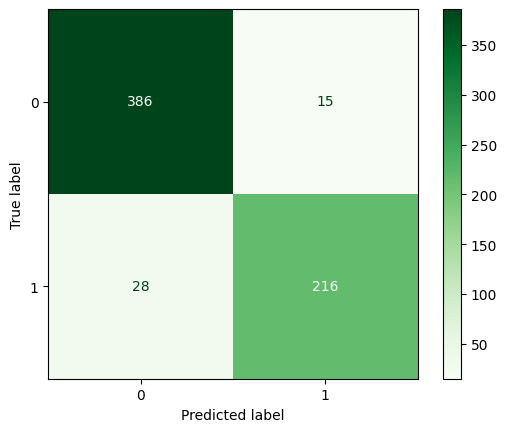

Normalized confusion matrix


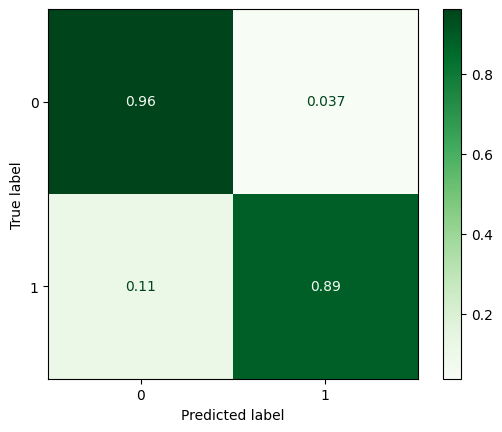

In [254]:
#Confusion matrix before normalization
print ('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap ='Greens')
plt.show()

# Confusion matrix after normalization
print ('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap ='Greens')
plt.show()

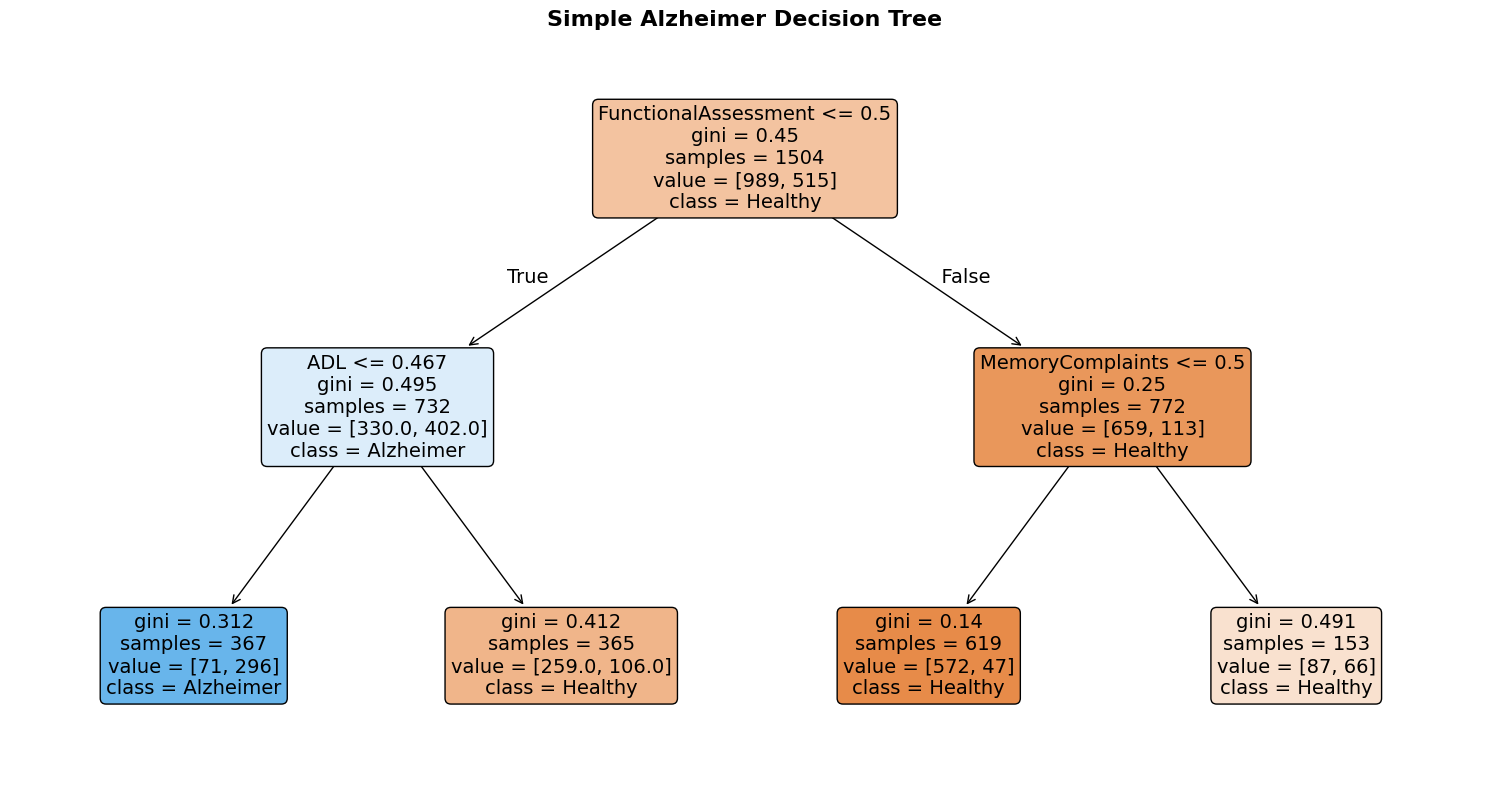

In [290]:
#simple tree
simple_tree = DecisionTreeClassifier(
    max_depth=2,           # Very shallow depth
    min_samples_split=100, # Requires many samples to split
    random_state=42
)

# Train the model
simple_tree.fit(X_train, y_train)

# Plot the simple tree
plt.figure(figsize=(15, 8))
plot_tree(simple_tree,
          feature_names=X.columns.tolist(),
          class_names=['Healthy', 'Alzheimer'],
          filled=True,
          rounded=True,
          fontsize=14)

plt.title('Simple Alzheimer Decision Tree', fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

## 4.Random Forest

In [255]:
#creating our Random Forest Model
RF = RandomForestClassifier(n_estimators=100, random_state=0)
#training our model
RF.fit(X_train, y_train)
#make predictions based on the X (training features) we gave
pred = RF.predict(X_test)

In [275]:
# Training accuracy
train_accuracy_rf = accuracy_score(y_train, RF.predict(X_train))
print("Random Forest Model's Accuracy while training: {:.2f}".format(train_accuracy_rf))

# Testing accuracy
test_accuracy_rf = accuracy_score(y_test, RF.predict(X_test))
print("Random Forest Model's Accuracy while testing: {:.2f}".format(test_accuracy_rf))

Random Forest Model's Accuracy while training: 1.00
Random Forest Model's Accuracy while testing: 0.91


In [256]:
#display Confusion matrix & classification
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[391  10]
 [ 51 193]]
              precision    recall  f1-score   support

         0.0       0.88      0.98      0.93       401
         1.0       0.95      0.79      0.86       244

    accuracy                           0.91       645
   macro avg       0.92      0.88      0.90       645
weighted avg       0.91      0.91      0.90       645



In [257]:
accuracy_rf = accuracy_score(y_test,pred)
jaccard_rf = jaccard_score(y_test, pred, pos_label=1)
f1_rf = f1_score(y_test, pred, pos_label=1)
log_loss_rf = log_loss(y_test, pred_proba)

print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Jaccard Score: {jaccard_rf:.4f}")
print(f"F1-Score: {f1_rf:.4f}")
print(f"Log Loss: {log_loss_rf:.4f}")

Accuracy: 0.9054
Jaccard Score: 0.7598
F1-Score: 0.8635
Log Loss: 0.4319


confusion matrix


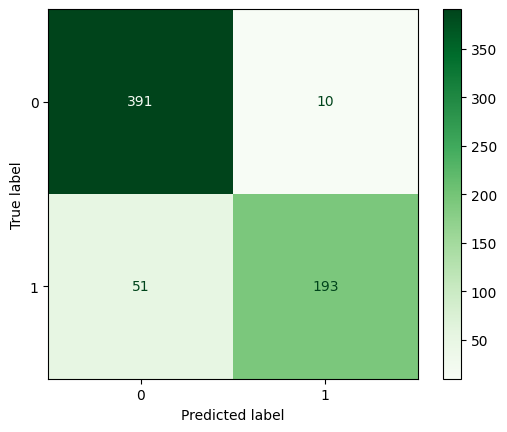

Normalized confusion matrix


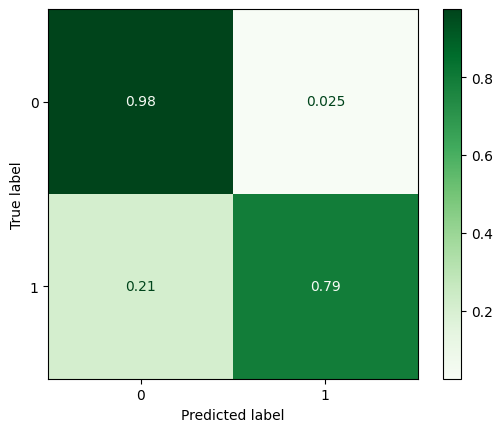

In [258]:
#Confusion matrix before normalization
print ('confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap ='Greens')
plt.show()

#Confusion matrix after normalization
print ('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap ='Greens')
plt.show()

## 5.Naive Bayes


In [259]:
#creating our object GNB model
GNB = GaussianNB()
#training our model
GNB.fit(X_train, y_train)
#make predictions based on the X (training features) we gave
pred = GNB.predict(X_test)
#To get probaility
pred_proba = GNB.predict_proba(X_test)


In [276]:
# Training accuracy
train_accuracy_nb = accuracy_score(y_train, GNB.predict(X_train))
print("Naive Bayes Model's Accuracy while training: {:.2f}".format(train_accuracy_nb))

# Testing accuracy
test_accuracy_nb = accuracy_score(y_test, GNB.predict(X_test))
print("Naive Bayes Model's Accuracy while testing: {:.2f}".format(test_accuracy_nb))

Naive Bayes Model's Accuracy while training: 0.83
Naive Bayes Model's Accuracy while testing: 0.81


In [260]:
#display Confusion matrix & classification
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[352  49]
 [ 76 168]]
              precision    recall  f1-score   support

         0.0       0.82      0.88      0.85       401
         1.0       0.77      0.69      0.73       244

    accuracy                           0.81       645
   macro avg       0.80      0.78      0.79       645
weighted avg       0.80      0.81      0.80       645



In [261]:
accuracy_nb = accuracy_score(y_test,pred)
jaccard_nb = jaccard_score(y_test, pred, pos_label=1)
f1_nb = f1_score(y_test, pred, pos_label=1)
log_loss_nb = log_loss(y_test, pred_proba)

print(f"Accuracy: {accuracy_nb:.4f}")
print(f"Jaccard Score: {jaccard_nb:.4f}")
print(f"F1-Score: {f1_nb:.4f}")
print(f"Log Loss: {log_loss_nb:.4f}")

Accuracy: 0.8062
Jaccard Score: 0.5734
F1-Score: 0.7289
Log Loss: 0.4312


Confusion matrix


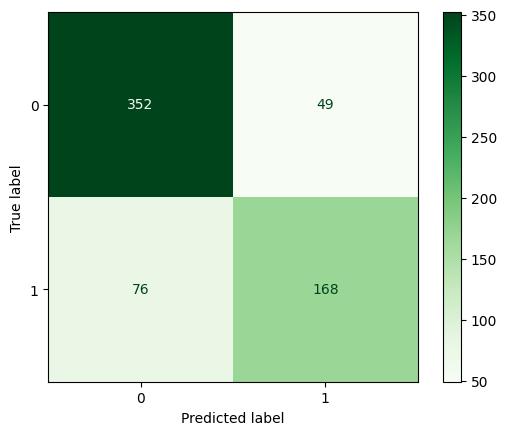

Normalized confusion matrix


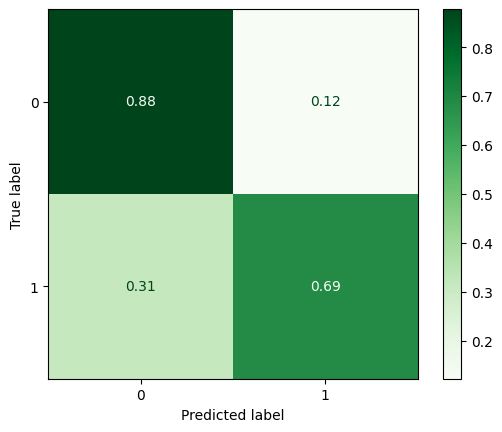

In [262]:
#Confusion matrix before normalization
print ('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap ='Greens')
plt.show()

#Confusion matrix after normalization
print ('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap ='Greens')
plt.show()

## 6.Support Vector Machine

In [263]:
#Creating our SVM model
SVC = make_pipeline(StandardScaler(),SVC(probability=True))

#training our model
SVC.fit(X_train, y_train)

#make predictions based on the X (training features) we gave
pred = SVC.predict(X_test)

In [278]:
# Training accuracy
train_accuracy_svm = accuracy_score(y_train, SVC.predict(X_train))
print("SVM Model's Accuracy while training: {:.2f}".format(train_accuracy_svm))

# Testing accuracy
test_accuracy_svm = accuracy_score(y_test, SVC.predict(X_test))
print("SVM Model's Accuracy while testing: {:.2f}".format(test_accuracy_svm))

SVM Model's Accuracy while training: 0.96
SVM Model's Accuracy while testing: 0.81


In [264]:
#displaying Confusion matrix, classification
print(confusion_matrix(y_test,pred))
print(classification_report(y_test,pred))

[[360  41]
 [ 84 160]]
              precision    recall  f1-score   support

         0.0       0.81      0.90      0.85       401
         1.0       0.80      0.66      0.72       244

    accuracy                           0.81       645
   macro avg       0.80      0.78      0.79       645
weighted avg       0.81      0.81      0.80       645



In [267]:
accuracy_svm = accuracy_score(y_test,pred)
jaccard_svm = jaccard_score(y_test, pred, pos_label=1)
f1_svm = f1_score(y_test, pred, pos_label=1)
log_loss_svm = log_loss(y_test, pred_proba)

print(f"Accuracy: {accuracy_svm:.4f}")
print(f"Jaccard Score: {jaccard_svm:.4f}")
print(f"F1-Score: {f1_svm:.4f}")
print(f"Log Loss: {log_loss_svm:.4f}")

Accuracy: 0.8062
Jaccard Score: 0.5614
F1-Score: 0.7191
Log Loss: 0.4312


Confusion matrix


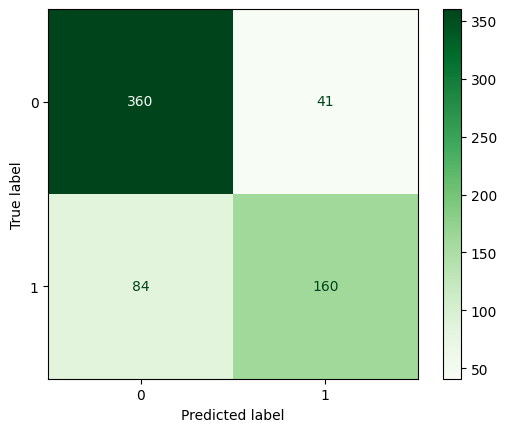

Normalized confusion matrix


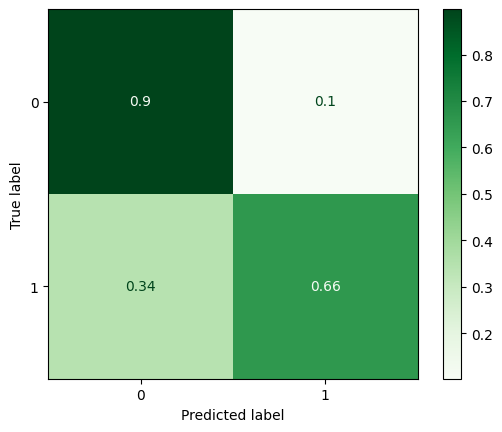

In [266]:
#confusion matrix before Normalization
print ('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap ='Greens')
plt.show()

#confusion matrix after Normalization
print ('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap ='Greens')
plt.show()


COMPREHENSIVE MODEL PERFORMANCE COMPARISON
Model                     Accuracy   Jaccard    F1-Score   LogLoss   
--------------------------------------------------------------------------------
Logistic Regression       0.8047     0.5655     0.7225     0.4319    
K-Nearest Neighbors       0.6636     0.2194     0.3599     NA        
Decision Tree             0.9333     0.8340     0.9095     NA        
Random Forest             0.9054     0.7598     0.8635     0.4319    
Naive Bayes               0.8062     0.5734     0.7289     0.4312    
Support Vector Machine    0.8062     0.5614     0.7191     0.4312    

BEST MODEL SELECTION RESULTS
Best model based on Accuracy: Decision Tree (Score: 0.9333)
Best model based on Jaccard : Decision Tree (Score: 0.8340)
Best model based on F1-Score: Decision Tree (Score: 0.9095)
Best model based on LogLoss: Naive Bayes (Score: 0.4312)

OVERALL RECOMMENDATION
OVERALL BEST MODEL: Decision Tree
   (Wins in 3 out of 4 evaluation metrics)

Performance Summ

<Figure size 1200x800 with 0 Axes>

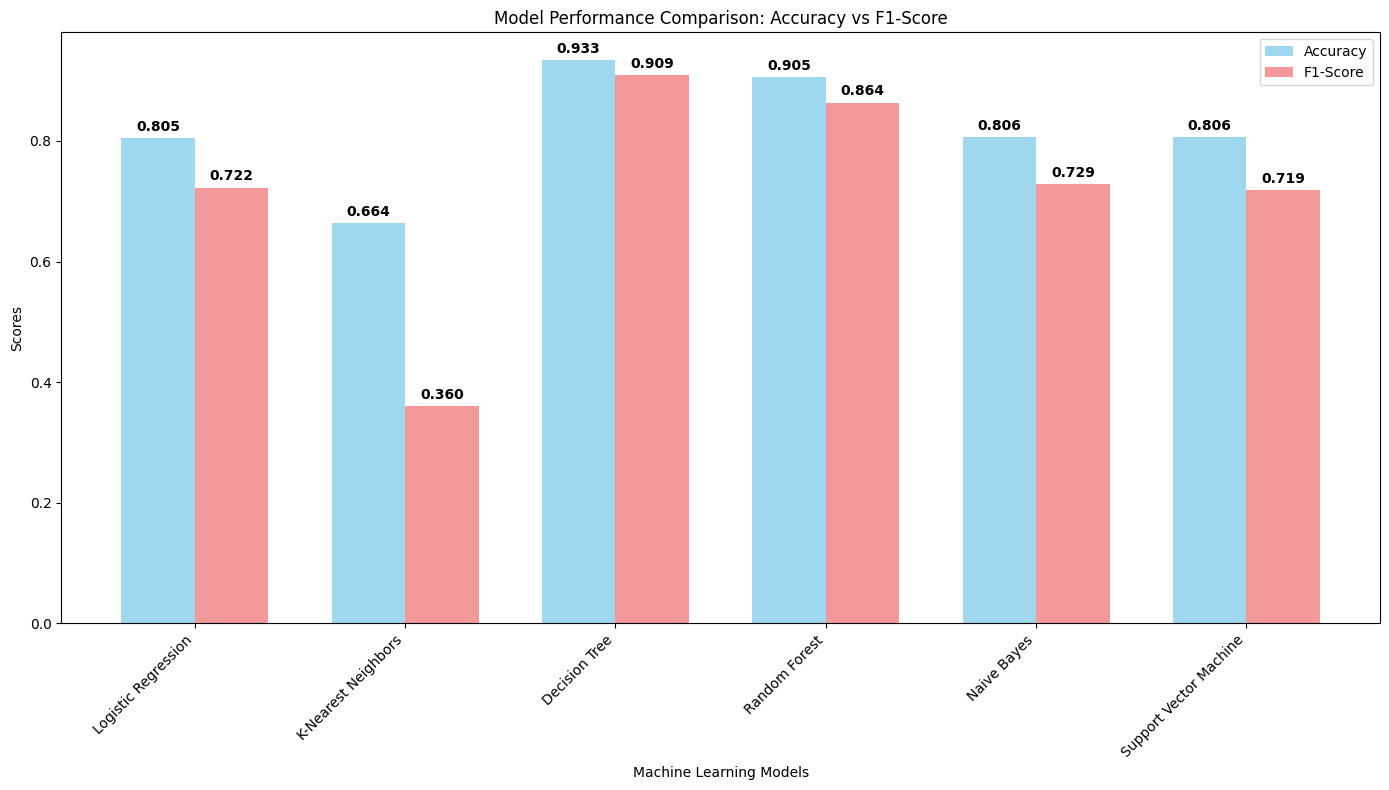

In [295]:
# Create a dictionary to store the evaluation metrics for each model
model_evaluations = {
    'Logistic Regression': {
        'Accuracy': accuracy_lr,
        'Jaccard': jaccard_lr,
        'F1-score': f1_lr,
        'LogLoss': log_loss_lr
    },
    'K-Nearest Neighbors': {
        'Accuracy': accuracy_knn,
        'Jaccard': jaccard_knn,
        'F1-score': f1_knn,
        'LogLoss': 'NA'  # KNN doesn't have reliable probability estimates
    },
    'Decision Tree': {
        'Accuracy': accuracy_dt,
        'Jaccard': jaccard_dt,
        'F1-score': f1_dt,
        'LogLoss': 'NA'  # Decision Tree doesn't provide reliable probability estimates
    },
    'Random Forest': {
        'Accuracy': accuracy_rf,
        'Jaccard': jaccard_rf,
        'F1-score': f1_rf,
        'LogLoss': log_loss_rf
    },
    'Naive Bayes': {
        'Accuracy': accuracy_nb,
        'Jaccard': jaccard_nb,
        'F1-score': f1_nb,
        'LogLoss': log_loss_nb
    },
    'Support Vector Machine': {
        'Accuracy': accuracy_svm,
        'Jaccard': jaccard_svm,
        'F1-score': f1_svm,
        'LogLoss': log_loss_svm
    }
}

# Display comprehensive results table
print("\n" + "=" * 80)
print("COMPREHENSIVE MODEL PERFORMANCE COMPARISON")
print("=" * 80)
print(f"{'Model':<25} {'Accuracy':<10} {'Jaccard':<10} {'F1-Score':<10} {'LogLoss':<10}")
print("-" * 80)

for model, metrics in model_evaluations.items():
    acc = f"{metrics['Accuracy']:.4f}" if metrics['Accuracy'] != 'NA' else 'NA'
    jac = f"{metrics['Jaccard']:.4f}" if metrics['Jaccard'] != 'NA' else 'NA'
    f1 = f"{metrics['F1-score']:.4f}" if metrics['F1-score'] != 'NA' else 'NA'
    logloss = f"{metrics['LogLoss']:.4f}" if metrics['LogLoss'] != 'NA' else 'NA'

    print(f"{model:<25} {acc:<10} {jac:<10} {f1:<10} {logloss:<10}")

# Function to determine the best model based on a given metric
def find_best_model(metric):
    best_model = None
    best_score = -1

    for model, metrics_dict in model_evaluations.items():
        if metric in metrics_dict:
            score = metrics_dict[metric]

            # Skip models with NA values
            if score == 'NA':
                continue

            if metric == 'LogLoss':  # Lower is better for LogLoss
                if best_score == -1 or score < best_score:
                    best_score = score
                    best_model = model
            else:  # Higher is better for other metrics
                if score > best_score:
                    best_score = score
                    best_model = model

    return best_model, best_score

# Find the best models for each metric
print("\n" + "=" * 50)
print("BEST MODEL SELECTION RESULTS")
print("=" * 50)

# Find best models
best_accuracy_model, best_accuracy_score = find_best_model('Accuracy')
best_jaccard_model, best_jaccard_score = find_best_model('Jaccard')
best_f1_model, best_f1_score = find_best_model('F1-score')
best_logloss_model, best_logloss_score = find_best_model('LogLoss')

print(f"Best model based on Accuracy: {best_accuracy_model} (Score: {best_accuracy_score:.4f})")
print(f"Best model based on Jaccard : {best_jaccard_model} (Score: {best_jaccard_score:.4f})")
print(f"Best model based on F1-Score: {best_f1_model} (Score: {best_f1_score:.4f})")
print(f"Best model based on LogLoss: {best_logloss_model} (Score: {best_logloss_score:.4f})")

# Overall best model recommendation
print("\n" + "=" * 60)
print("OVERALL RECOMMENDATION")
print("=" * 60)

# Count how many times each model is the best
model_wins = {}
for model in model_evaluations.keys():
    model_wins[model] = 0

winners = [best_accuracy_model, best_jaccard_model, best_f1_model, best_logloss_model]
for winner in winners:
    if winner in model_wins:
        model_wins[winner] += 1

# Find overall best model
overall_best_model = max(model_wins, key=model_wins.get)
total_wins = model_wins[overall_best_model]

print(f"OVERALL BEST MODEL: {overall_best_model}")
print(f"   (Wins in {total_wins} out of 4 evaluation metrics)")

print(f"\nPerformance Summary for {overall_best_model}:")
best_metrics = model_evaluations[overall_best_model]
for metric, value in best_metrics.items():
    if value != 'NA':
        print(f"   • {metric}: {value:.4f}")


# Visualization of model comparison
plt.figure(figsize=(12, 8))

# Prepare data for plotting
models = list(model_evaluations.keys())
accuracies = [model_evaluations[model]['Accuracy'] if model_evaluations[model]['Accuracy'] != 'NA' else 0 for model in models]
f1_scores = [model_evaluations[model]['F1-score'] if model_evaluations[model]['F1-score'] != 'NA' else 0 for model in models]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 8))
rects1 = ax.bar(x - width/2, accuracies, width, label='Accuracy', alpha=0.8, color='skyblue')
rects2 = ax.bar(x + width/2, f1_scores, width, label='F1-Score', alpha=0.8, color='lightcoral')

ax.set_xlabel('Machine Learning Models')
ax.set_ylabel('Scores')
ax.set_title('Model Performance Comparison: Accuracy vs F1-Score')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right')
ax.legend()

# Add value labels on bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                   xy=(rect.get_x() + rect.get_width() / 2, height),
                   xytext=(0, 3),
                   textcoords="offset points",
                   ha='center', va='bottom', fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()